In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from utils import (get_data, get_rc_and_err)

In [2]:
EMB_FILE   = '/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root'
HERWIG_PREFIX = '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig'
PYTHIA8_PREFIX= '/nfs/roberts/pi/pi_lbh35/youqi/detroit_tune/pythia'

PTHAT_BINS = ['50pthat1000', '45pthat50', '40pthat45', '35pthat40', '30pthat35',
                '25pthat30', '20pthat25', '15pthat20', '11pthat15']

COLUMNS = ['pt', 'b', 'w', 'y1', 'y2', 'phi1', 'phi2', 'pts', 'bs', 'ws', 'y1s', 'y2s', 'phi1s', 'phi2s']
TRUTH_COLS = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2','dr','m','nparents1','nparents2']

PT_EDGES   = [15, 20, 25, 30, 40, 60]
PT_CENTERS = [17.5, 22.5, 27.5, 35, 50]
PT_XERR    = [2.5, 2.5, 2.5, 5, 10]

plt.rcParams['figure.dpi']         = 120
plt.rcParams['font.family']        = 'arial'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
def bin_df_in_pt(df):
    return [df[(df.pt > PT_EDGES[i]) & (df.pt < PT_EDGES[i+1])] for i in range(5)]

def get_rc_and_err_arr(df_arr, ob):
    rc_arr, err_arr = [], []
    for df in df_arr:
        rc, err = get_rc_and_err(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_mc(observables, filename_prefix, pthat_bins):
    dfs = []
    for pthat_bin in pthat_bins:
        df = pd.read_csv(f'{filename_prefix}_{pthat_bin}_rc_truth.txt', names=observables, low_memory=False)
        df['w'] = float(df.iloc[-1]['xsec']) / 200000
        dfs.append(df)
    return pd.concat(dfs)

In [4]:
# PYTHIA6
df_pythia6 = get_data(COLUMNS, EMB_FILE, 'MatchedTree').query('b!=0 and b!=-9 and pt>15')
rc_pythia6, err_pythia6 = get_rc_and_err_arr(bin_df_in_pt(df_pythia6), 'b')
print('PYTHIA6 rc:', rc_pythia6)

PYTHIA6 rc: [-0.37972550416152645, -0.37892501746580687, -0.379498055300157, -0.3756346547416006, -0.37087323852796983]


In [9]:
# HERWIG7
df_herwig_raw = get_mc(TRUTH_COLS, HERWIG_PREFIX, PTHAT_BINS)
df_herwig = df_herwig_raw[['pt', 'q1', 'q2', 'w']].query('pt>15')
df_herwig.eval('b_ch = q1 * q2', inplace=True)
df_herwig.query('b_ch!=0 and b_ch!=-9', inplace=True) 
rc_herwig, err_herwig = get_rc_and_err_arr(bin_df_in_pt(df_herwig), 'b_ch')
print('HERWIG7 rc:', rc_herwig)

HERWIG7 rc: [-0.3707934738159463, -0.369657303517922, -0.3546488655195677, -0.3414189829377067, -0.3438688624769227]


In [6]:
# PYTHIA8
df_pythia8_raw = get_mc(TRUTH_COLS, PYTHIA8_PREFIX, PTHAT_BINS)
df_pythia8 = df_pythia8_raw[['pt', 'q1', 'q2', 'w']].query('pt>15')
df_pythia8.eval('b_ch = q1 * q2', inplace=True)
df_pythia8.query('b_ch!=0 and b_ch!=-9', inplace=True) 
rc_pythia8, err_pythia8 = get_rc_and_err_arr(bin_df_in_pt(df_pythia8), 'b_ch')
print('PYTHIA8 rc:', rc_pythia8)

PYTHIA8 rc: [-0.37272321800756153, -0.3653815849505942, -0.36020371647364763, -0.3690612303261614, -0.3634228357237977]


In [14]:
# central values and stat. uncertainty
rc_nom     = np.array([-0.3362253643675409, -0.3181884886244119, -0.3182451746120078, -0.31383135754427693, -0.3356494741663978]) # fig3_fig5 output
rc_nom_err = np.array([0.00441068, 0.00361316, 0.0048446,  0.00800724, 0.02197407]) # fig3_fig5 output

# systematic uncertainty
rc_tow104    = np.array([-0.33410201908181153, -0.3186500106234434, -0.3197666112067066, -0.3160997178344868, -0.33862417659089133]) # systematic_detector output
rc_eff096    = np.array([-0.3397437289480048, -0.3177811564600664, -0.3191365800826993, -0.31285443133371865, -0.33065029152367026]) # systematic_detector output
rc_hadcorr05 = np.array([-0.33492386693534776, -0.31918113493024397, -0.31951323942139137, -0.3160111160658111, -0.3435692254657506]) # systematic_detector output
rc_dr03      = np.array([-0.3365891545550252, -0.31833969647739513, -0.31766934093618665, -0.3134515100646791, -0.33379041888696503]) # systematic_dr03 output
rc_rw        = np.array([-0.3363383503313372, -0.31858421634077183, -0.31837883403935097, -0.3137246463351878, -0.33749948103192695]) # systematic_reweighted_pt output
rc_hw_prior  = np.array([-0.3370650460872254, -0.3188489298761159, -0.30993353131613866, -0.3047069959032681, -0.340315556868172]) # systematic_herwig_prior output
rc_nonclosure_err = 0.01 * abs(rc_nom)
sys_err = np.sqrt((rc_tow104    - rc_nom)**2 +
                  (rc_eff096    - rc_nom)**2 +
                  (rc_hadcorr05 - rc_nom)**2 +
                  (rc_nonclosure_err)    **2 +
                  (rc_dr03      - rc_nom)**2 +
                  (rc_rw        - rc_nom)**2 +
                  (rc_hw_prior  - rc_nom)**2)

print('sys_err:', sys_err)
print('rc_nom - sys_err:', rc_nom - sys_err)
print('rc_nom + sys_err:', rc_nom + sys_err)

# Random track pairs in jets (STAR data, 3 central pT bins)
rc_random     = np.array([-0.22518997953719813, -0.21441642135412523, -0.2129313872595826])
rc_random_err = np.array([0.002925290181545458, 0.006160481432193258, 0.01141150183243689])

sys_err: [0.00554403 0.00347912 0.00918032 0.01020342 0.01168247]
rc_nom - sys_err: [-0.3417694  -0.32166761 -0.32742549 -0.32403478 -0.34733195]
rc_nom + sys_err: [-0.33068133 -0.31470936 -0.30906486 -0.30362793 -0.323967  ]


findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.


findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.


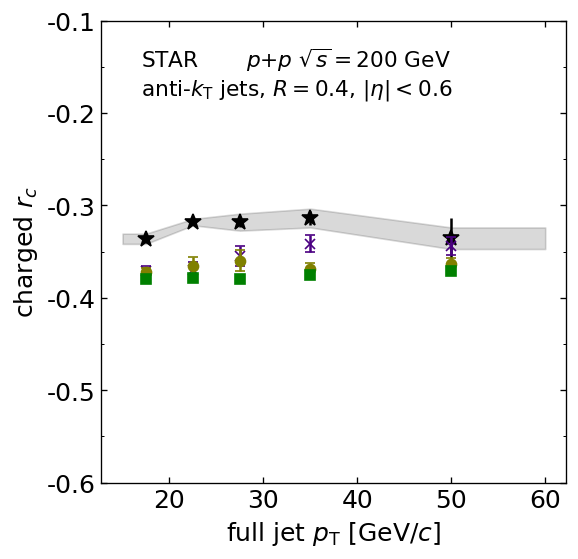

In [15]:
plt.rcParams['font.size'] = 15

# Expand systematic band to step function spanning full bin widths
x_fill  = [PT_EDGES[0]] + PT_CENTERS + [PT_EDGES[-1]]
lo_fill = [rc_nom[0] - sys_err[0]] + list(rc_nom - sys_err) + [rc_nom[-1] - sys_err[-1]]
hi_fill = [rc_nom[0] + sys_err[0]] + list(rc_nom + sys_err) + [rc_nom[-1] + sys_err[-1]]

fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(PT_CENTERS, rc_nom, yerr=rc_nom_err, capsize=0, ls='none', color='k')
nom, = ax.plot(PT_CENTERS, rc_nom, ls='none', marker='*', markersize=10, label='Corrected STAR data', color='k')
ax.fill_between(x_fill, lo_fill, hi_fill, alpha=0.15, color='k')

ax.errorbar(PT_CENTERS, rc_herwig, yerr=err_herwig, capsize=3, color='indigo', ls='none')
herwig, = ax.plot(PT_CENTERS, rc_herwig, color='indigo', ls='none', label='HERWIG7 default tune', marker='x')

ax.errorbar(PT_CENTERS, rc_pythia8, yerr=err_pythia8, capsize=3, color='olive', ls='none')
pythia8, = ax.plot(PT_CENTERS, rc_pythia8, color='olive', ls='none', label='PYTHIA8 Detroit tune', marker='o')

ax.errorbar(PT_CENTERS, rc_pythia6, yerr=err_pythia6, capsize=3, color='g', ls='none')
pythia6, = ax.plot(PT_CENTERS, rc_pythia6, color='g', ls='none', label='PYTHIA6 STAR tune', marker='s')

# eb1 = ax.errorbar([22.5, 27.5, 35], rc_random, xerr=[2.5, 2.5, 5], yerr=rc_random_err,
#                   ls='none', label='Random track pairs in jets (STAR data)', color='k', capsize=3)
# eb1[-1][0].set_linestyle('--')
# eb1[-1][1].set_linestyle('--')

ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('charged $r_c$')
ax.set_ylim(-0.6, -0.1)
ax.text(17, -0.15, 'STAR       $p$+$p$ $\\sqrt{s}=200$ GeV', fontsize=13)
ax.text(17, -0.18, r'anti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
# ax.legend(handles=[nom, herwig, pythia8, pythia6, eb1], fontsize=12, loc='lower left', frameon=False)
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.yaxis.set_minor_locator(MultipleLocator(0.05))
# plt.savefig('fig9.png', bbox_inches='tight')
# plt.savefig('fig9.pdf', bbox_inches='tight')
plt.show()

In [16]:
print(rc_hw_prior / rc_nom)

[1.00249738 1.00207563 0.97388289 0.97092591 1.01390165]


findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

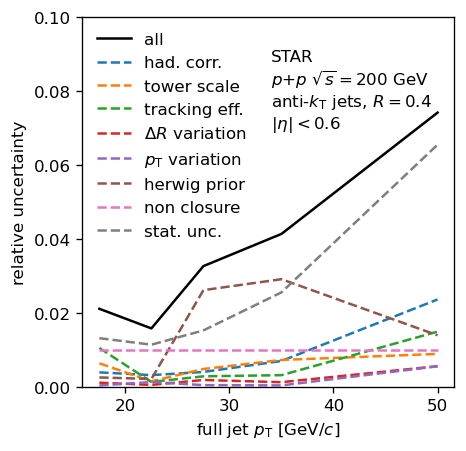

In [24]:
plt.rcParams['font.size'] = 10

fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(PT_CENTERS, abs(np.sqrt(sys_err**2 + rc_nom_err**2) / rc_nom), label='all',                   color='k')
ax.plot(PT_CENTERS, abs((rc_hadcorr05 - rc_nom) / rc_nom),             label='had. corr.',            linestyle='--')
ax.plot(PT_CENTERS, abs((rc_tow104    - rc_nom) / rc_nom),             label='tower scale',           linestyle='--')
ax.plot(PT_CENTERS, abs((rc_eff096    - rc_nom) / rc_nom),             label='tracking eff.',         linestyle='--')
ax.plot(PT_CENTERS, abs((rc_dr03      - rc_nom) / rc_nom),             label=r'$\Delta R$ variation', linestyle='--')
ax.plot(PT_CENTERS, abs((rc_rw        - rc_nom) / rc_nom),             label=r'$p_{\mathrm{T}}$ variation', linestyle='--')
ax.plot(PT_CENTERS, abs((rc_hw_prior  - rc_nom) / rc_nom),             label='herwig prior',          linestyle='--')
ax.plot(PT_CENTERS, abs(rc_nonclosure_err / rc_nom),                   label='non closure',           linestyle='--')
ax.plot(PT_CENTERS, abs(rc_nom_err / rc_nom),                          label='stat. unc.',            linestyle='--')
ax.set_xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]')
ax.set_ylabel('relative uncertainty')
ax.set_ylim(0, 0.1)
ax.legend(frameon=False, loc='upper left')
ax.text(34, 0.07, 'STAR\n$p$+$p$ $\\sqrt{s}=200$ GeV\n'
        r'anti-$k_\mathrm{T}$ jets, $R=0.4$' '\n' r'$|\eta|<0.6$')
# plt.savefig('fig10.png', bbox_inches='tight')
plt.show()